# 04 — Treinamento, Otimização e Comparação dos Modelos

**Objetivo.** Estimar $f(\mathbf{X}_{i,T})$ para a variação do valor de mercado em $T+1$ e $T+2$,
comparando três *ensembles* de árvores (Random Forest, XGBoost e CatBoost) com *baselines*
lineares (OLS e Ridge) e com uma referência ingênua. Isso é feito em duas arquiteturas: um
**modelo global**, que recebe faixa etária e posição como variáveis, e **12 modelos segmentados**,
um por categoria C1–C12 (especificação, §6.3–6.6).

**Entrada:** `data/processed/train_test_lags.parquet` e `feature_sets.json` (notebook 03).
**Saídas:**
- modelos finais em `models/04_model_training/final/`, com manifesto;
- previsões fora da amostra em `data/processed/predictions_oof.parquet`;
- tabelas e figuras em `reports/`.

### Versão 2: melhorias para a estimativa da magnitude

A primeira versão (v1) ordenava bem os atletas, mas estimava mal **quanto** cada um se valoriza.
Faltava capacidade de antecipar saltos, e havia dois problemas na conversão da previsão. Este
notebook incorpora quatro melhorias, cada uma avaliada sem olhar o futuro:

1. **Novas *features*** (notebook 03): oito variáveis de dinâmica das reavaliações do
   Transfermarkt e o **gap de avaliação** (valor justo pelo desempenho em $T$ menos $V_T$).
2. ***Ensemble*** da média de CatBoost, XGBoost e Ridge globais, como candidato à arquitetura
   final.
3. **Camada de magnitude:** recalibração linear e correção de retransformação por *smearing*
   (Duan, 1983) por faixa etária, estimadas apenas com as dobras anteriores. Ela fornece dois
   pontos de previsão:
   - a **mediana** $e^{\hat y}-1$, adequada ao erro absoluto;
   - a **esperança** $\hat f\,e^{\hat y}-1$, adequada ao erro quadrático e a somas em €.
4. **Intervalos de 80% (P10–P90)** por CatBoost quantílico, conformalizados sequencialmente
   (Romano et al., 2019). Exprimem a magnitude como faixa de cenários.

As métricas da v1 ficam em `reports/tables/04_model_training/v1_baseline/` para comparação.

## Desenho experimental

| Elemento | Definição |
|---|---|
| Alvo de treino | log-retorno $y = \ln(V_{T+k}/V_T)$. As previsões são reconvertidas para $\Delta V\% = (e^{\hat y}-1)\times 100$ e $\Delta V = V_T(e^{\hat y}-1)$ |
| Validação | janela expandida: 4 dobras em $T+1$ (teste de 2020/21 a 2023/24) e 3 dobras em $T+2$, com purga de uma temporada (teste de 2021/22 a 2023/24) |
| Otimização de hiperparâmetros | bayesiana com processo gaussiano (`skopt.gp_minimize`, aquisição *gp_hedge*), minimizando a RMSE média nas dobras de **validação**, isto é, todas menos a última |
| Teste final | a última dobra (teste em 2023/24) nunca participa da escolha de hiperparâmetros nem da seleção de modelos |
| Pré-processamento (dentro da dobra) | mediana do treino por posição para ausentes. Nos lineares, também winsorização em p1/p99 e escalonamento robusto (mediana/IQR). *Dummies* de liga, e de faixa etária e posição no modelo global |
| Modelos | mediana do treino (ingênuo), OLS (vetor compacto de 22 variáveis, um representante por bloco correlacionado), Ridge, Random Forest, XGBoost e CatBoost |
| Métricas | RMSE, MAE e $R^2$ nas três escalas do alvo (log-retorno, $\Delta V\%$, $\Delta V$ em €), $\rho$ de Spearman e taxa de acerto do decil superior (dos 10% com maior valorização prevista, quantos se valorizaram) |

**Orçamento computacional e desvios da especificação.** O experimento soma 156 tarefas
(2 horizontes × 13 escopos × 6 algoritmos). Ele roda num processador de 4 núcleos (i5-10300H),
em que uma única Random Forest global com `max_features = 0,5` leva cerca de 4 minutos. Para que o
experimento fosse executável, foram adotados os seguintes cortes, que devem constar na Metodologia:

- **Número de avaliações:** 15 por otimização no modelo global e 10 em cada categoria. Metade são
  pontos iniciais aleatórios e metade é guiada pelo processo gaussiano.
- **Tetos dos hiperparâmetros:**
  - XGBoost: até 800 árvores (especificação: 1.000);
  - CatBoost: até 800 iterações (especificação: 1.200) e profundidade até 8 (especificação: 10);
  - Random Forest: até 500 árvores (especificação: 800), com `max_features` em {sqrt, log2, 0,3}.
- **Velocidade dos boostings:** histogramas com 64 *bins* no XGBoost e no CatBoost. No CatBoost,
  amostra de 50% das variáveis em cada divisão (`rsm = 0,5`).

Os demais intervalos seguem a especificação.

## 0. Configuração

In [1]:
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from joblib import Parallel, delayed, parallel_config

from football_analytics import feature_catalog as fc
from football_analytics import modeling as md
from football_analytics import plotting as pl
from football_analytics import sample as sp
from football_analytics.config import default_config
from football_analytics.io import load_table, save_table
from football_analytics.logging_utils import setup_logging
from football_analytics.validation import Fold

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

import os

# FA_SMOKE_TEST=1: 15% das linhas e 5 avaliações por otimização, com saídas em data/smoke_test/04/
SMOKE_TEST = os.environ.get("FA_SMOKE_TEST") == "1"
cfg = default_config()
paths = cfg.paths
logger = setup_logging(paths.logs / "04_model_training.log")
pl.setup_style()
OUT = paths.root / "data" / "smoke_test" / "04" if SMOKE_TEST else None
FIG = pl.FigureRegistry(OUT / "figures" if SMOKE_TEST else paths.figures("04_model_training"),
                        source="Elaboração própria com dados de FBref, Understat, Sofascore e Transfermarkt (2026)")
TABLES = OUT / "tables" if SMOKE_TEST else paths.tables("04_model_training")
TABLES.mkdir(parents=True, exist_ok=True)
MODELS_DIR = OUT / "models" if SMOKE_TEST else paths.root / "models" / "04_model_training"
PROCESSED_OUT = OUT if SMOKE_TEST else paths.processed
CACHE = MODELS_DIR / "cache"
FINAL = MODELS_DIR / "final"


def save_csv(df: pd.DataFrame, name: str, index: bool = True) -> None:
    df.to_csv(TABLES / f"{name}.csv", index=index, encoding="utf-8-sig", float_format="%.5f")


N_JOBS = 8
N_CALLS = {"global": 5, "segment": 5} if SMOKE_TEST else {"global": 15, "segment": 10}
SPECS = {"global": md.model_specs(N_CALLS["global"], N_CALLS["global"]),
         "segment": md.model_specs(N_CALLS["segment"], N_CALLS["segment"])}
MODELS = ["median", "ols", "ridge", "rf", "xgb", "cat"]
MODEL_LABELS = {k: SPECS["global"][k].label for k in MODELS}
CATEGORIES = [f"C{i}" for i in range(1, 13)]
CAT_LABELS = sp.category_labels()
HORIZONS = (1, 2)

In [2]:
panel = load_table(paths.processed / "train_test_lags.parquet")
if SMOKE_TEST:
    panel = panel.groupby(["season", "category"], group_keys=False).sample(frac=0.15, random_state=0)
fs = json.loads((paths.processed / "feature_sets.json").read_text(encoding="utf-8"))
NUMERIC = tuple(fs["numeric_features"])
LOOKAHEAD = tuple(fs["lookahead_features"])
CAT_GLOBAL = ("league", "age_band", "position_group")
CAT_SEGMENT = ("league",)
folds = {k: [Fold(tuple(f["train"]), f["test"], tuple(f["purged"])) for f in fs["folds"][f"T{k}"]] for k in HORIZONS}
print(f"Painel: {len(panel):,} linhas | {len(NUMERIC)} features numéricas | dobras: "
      + ", ".join(f"T+{k}: {len(v)}" for k, v in folds.items()))
for k, fl in folds.items():
    print(f"  T+{k}: validação = " + "; ".join(f"{','.join(f.train)}→{f.test}" for f in fl[:-1])
          + f" | teste final = {fl[-1].test}")

Painel: 9,810 linhas | 105 features numéricas | dobras: T+1: 4, T+2: 3
  T+1: validação = 1920→2021; 1920,2021→2122; 1920,2021,2122→2223 | teste final = 2324
  T+2: validação = 1920→2122; 1920,2021→2223 | teste final = 2324


## 1. Execução das tarefas

Cada tarefa (horizonte × escopo × algoritmo) segue três passos: otimiza os hiperparâmetros nas
dobras de validação, avalia em todas as dobras com os hiperparâmetros escolhidos e grava o
resultado em cache (`models/04_model_training/cache/`). Reexecutar o notebook reaproveita o cache.
As tarefas rodam em paralelo, com um processo e uma *thread* por modelo.

In [3]:
tasks = [md.Task(k, scope, m, NUMERIC, CAT_GLOBAL if scope == "global" else CAT_SEGMENT)
         for k in HORIZONS for m in MODELS for scope in ["global", *CATEGORIES]]
cost = {"rf": 6.0, "cat": 3.0, "xgb": 2.0, "ridge": 0.1, "ols": 0.05, "median": 0.01}
size = panel.groupby("category").size()
order = sorted(tasks, key=lambda t: -cost[t.model] * (len(panel) if t.scope == "global" else size[t.scope]))


def execute(task: md.Task, fixed: dict | None = None) -> dict:
    specs = SPECS["global" if task.scope == "global" else "segment"]
    return md.run_task(task, panel, folds[task.horizon], folds[task.horizon][:-1], specs, CACHE, fixed_params=fixed)


cached = sum((CACHE / f"{t.key()}.joblib").exists() for t in tasks)
print(f"{len(tasks)} tarefas; {cached} já em cache")
t0 = time.time()
with parallel_config(backend="loky", inner_max_num_threads=1):
    results = Parallel(n_jobs=N_JOBS, verbose=0)(delayed(execute)(t) for t in order)
print(f"concluído em {(time.time() - t0) / 60:,.1f} min")

156 tarefas; 156 já em cache


concluído em 0.2 min


In [4]:
# Robustez: modelo global XGBoost com as variáveis contratuais sujeitas a look-ahead
# (notebook 03, seção 3), com os mesmos hiperparâmetros do modelo principal.
by_key = {(r["task"].horizon, r["task"].scope, r["task"].model): r for r in results}
robust = [execute(md.Task(k, "global", "xgb", NUMERIC + LOOKAHEAD, CAT_GLOBAL, extra_label="lookahead"),
                  fixed=by_key[(k, "global", "xgb")]["params"]) for k in HORIZONS]

# Quantis P10 e P90: CatBoost global com perda quantílica e os hiperparâmetros do modelo principal.
q_tasks = [(md.Task(k, "global", "cat", NUMERIC, CAT_GLOBAL, extra_label=f"q{int(q * 100)}"),
            by_key[(k, "global", "cat")]["params"] | {"loss_function": f"Quantile:alpha={q}"})
           for k in HORIZONS for q in (0.1, 0.9)]
with parallel_config(backend="loky", inner_max_num_threads=1):
    quantiles = Parallel(n_jobs=4)(delayed(execute)(t, fixed=f) for t, f in q_tasks)

timing = (pd.DataFrame([{"horizonte": f"T+{r['task'].horizon}", "escopo": "Global" if r["task"].scope == "global" else "Categoria",
                         "modelo": MODEL_LABELS[r["task"].model], "segundos": r["seconds"]} for r in results])
          .groupby(["horizonte", "escopo", "modelo"])["segundos"].sum().unstack("horizonte").div(60))
save_csv(timing, "tab01_tempo_computacional_min")
timing.round(1)

horizonte                                  T+1     T+2
escopo    modelo                                      
Categoria CatBoost                    104.8000 66.7000
          Mediana do treino (ingênuo)   0.0000  0.0000
          OLS                           0.4000  0.3000
          Random Forest                38.2000 22.0000
          Ridge                        15.1000 10.7000
          XGBoost                      11.7000  9.6000
Global    CatBoost                     17.0000 11.9000
          Mediana do treino (ingênuo)   0.0000  0.0000
          OLS                           0.0000  0.0000
          Random Forest                42.2000 19.8000
          Ridge                         2.2000  1.5000
          XGBoost                       3.7000  3.9000

## 2. Hiperparâmetros otimizados e convergência

A figura mostra, para os modelos globais, a melhor RMSE de validação obtida até cada avaliação. As
primeiras avaliações são aleatórias; as seguintes são escolhidas pelo processo gaussiano.

,horizonte,modelo,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,depth,learning_rate,l2_leaf_reg,iterations,subsample,colsample_bytree,gamma,reg_alpha,reg_lambda,alpha
0,T+1,Random Forest,143.0000,24.0000,10.0000,5.0000,0.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,T+2,Random Forest,491.0000,24.0000,10.0000,5.0000,sqrt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,T+1,CatBoost,NaN,NaN,NaN,NaN,NaN,8.0000,0.0135,9.7944,202.0000,NaN,NaN,NaN,NaN,NaN,NaN
3,T+2,CatBoost,NaN,NaN,NaN,NaN,NaN,7.0000,0.0308,7.5995,200.0000,NaN,NaN,NaN,NaN,NaN,NaN
4,T+1,XGBoost,100.0000,7.0000,NaN,NaN,NaN,NaN,0.0360,NaN,NaN,0.8159,0.9762,2.9652,10.0000,0.0128,NaN
5,T+2,XGBoost,800.0000,10.0000,NaN,NaN,NaN,NaN,0.0100,NaN,NaN,0.6000,0.7659,5.0000,0.0010,10.0000,NaN
6,T+1,Ridge,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.3396
7,T+2,Ridge,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,61.1757


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/04_model_training/fig01_convergencia_otimizacao.png


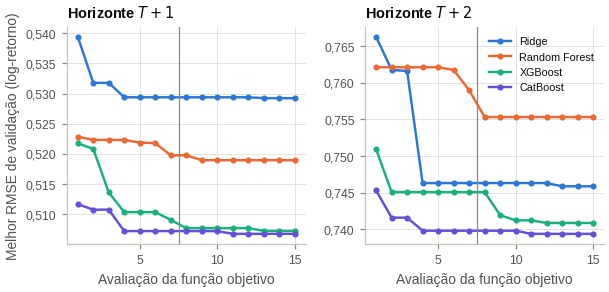

In [5]:
hp = pd.DataFrame([{"horizonte": f"T+{r['task'].horizon}", "modelo": MODEL_LABELS[r["task"].model],
                    **{k: v for k, v in r["params"].items()}}
                   for r in results if r["task"].scope == "global" and r["params"]])
save_csv(hp, "tab02_hiperparametros_globais", index=False)
display(hp)

seg_hp = pd.DataFrame([{"horizonte": f"T+{r['task'].horizon}", "categoria": r["task"].scope,
                        "modelo": MODEL_LABELS[r["task"].model], "params": json.dumps(r["params"])}
                       for r in results if r["task"].scope != "global" and r["params"]])
save_csv(seg_hp, "tab03_hiperparametros_segmentados", index=False)

fig, axes = plt.subplots(1, 2, figsize=pl.figsize(6.5), sharey=False, gridspec_kw={"wspace": 0.25})
colors = {"ridge": pl.BLUE, "rf": pl.ORANGE, "xgb": pl.AQUA, "cat": "#6250d6"}
for ax, k in zip(axes, HORIZONS):
    for m, color in colors.items():
        hist = by_key[(k, "global", m)]["history"]
        ax.plot(range(1, len(hist) + 1), np.minimum.accumulate(hist), color=color, marker="o", markersize=3,
                linewidth=1.6, label=MODEL_LABELS[m])
    ax.axvline(N_CALLS["global"] // 2 + 0.5, color=pl.INK_MUTED, linewidth=0.8)
    ax.set_title(f"Horizonte $T+{k}$")
    ax.set_xlabel("Avaliação da função objetivo")
    ax.yaxis.set_major_formatter(pl.br_formatter(3))
axes[0].set_ylabel("Melhor RMSE de validação (log-retorno)")
axes[1].legend(loc="upper right", fontsize=7)
FIG.save(fig, "fig01_convergencia_otimizacao",
         "Convergência da otimização bayesiana dos hiperparâmetros dos modelos globais",
         note="À esquerda da linha vertical, pontos iniciais aleatórios; à direita, pontos escolhidos pelo processo gaussiano.")
plt.show()

## 3. Previsões fora da amostra e métricas

As previsões dos 12 modelos segmentados são unidas para formar a abordagem **segmentada**, que
cobre as mesmas observações do modelo global. Além dos algoritmos, há a referência **"sem
variação"** ($\hat y = 0$, isto é, $V_{T+k} = V_T$).

As métricas são reportadas de duas formas:
- no **teste final** (2023/24), que é a avaliação limpa;
- como **média das dobras** da janela expandida, que segue a especificação, §5, mas inclui as
  dobras usadas na otimização e é, portanto, levemente otimista.

In [6]:
preds = []
for r in results + robust:
    t = r["task"]
    preds.append(r["predictions"].assign(horizon=t.horizon, scope=t.scope, model=t.model, extra=t.extra_label))
pred = pd.concat(preds, ignore_index=True)
pred["approach"] = np.where(pred["scope"] == "global", "Global", "Segmentado")
main = pred[pred["extra"] == ""]
zero = (main[(main["approach"] == "Global") & (main["model"] == "median")]
        .assign(model="zero", y_pred=0.0))
main = pd.concat([main, zero], ignore_index=True)
# Ensemble: média simples (sem pesos ajustados, portanto sem otimização adicional) dos globais.
ENSEMBLE = ["cat", "xgb", "ridge"]
members = main[(main["approach"] == "Global") & main["model"].isin(ENSEMBLE)]
avg = (members.groupby(["horizon", "season", "fbref_player_id"], as_index=False)
       .agg(y_pred=("y_pred", "mean"), n_members=("model", "size")))
avg = avg[avg["n_members"] == len(ENSEMBLE)].drop(columns="n_members")
ens = (main[(main["approach"] == "Global") & (main["model"] == "cat")].drop(columns="y_pred")
       .merge(avg, on=["horizon", "season", "fbref_player_id"]).assign(model="ens"))
main = pd.concat([main, ens], ignore_index=True)
LABELS = {**MODEL_LABELS, "zero": "Sem variação (V_{T+k} = V_T)", "ens": "Ensemble (CatBoost + XGBoost + Ridge)"}


def metrics_by(df: pd.DataFrame, by: list[str]) -> pd.DataFrame:
    return df.groupby(by).apply(md.regression_metrics).reset_index()


holdout = metrics_by(main[main["is_holdout"]], ["horizon", "approach", "model"])
per_fold = metrics_by(main, ["horizon", "approach", "model", "fold"])
cv_mean = per_fold.groupby(["horizon", "approach", "model"]).mean(numeric_only=True).drop(columns="fold").reset_index()
validation = per_fold.merge(pd.DataFrame([(k, len(folds[k])) for k in HORIZONS], columns=["horizon", "n_folds"]))
validation = (validation[validation["fold"] < validation["n_folds"]]
              .groupby(["horizon", "approach", "model"])["RMSE_log"].mean().rename("RMSE_log_validacao").reset_index())
cols = ["n", "RMSE_log", "MAE_log", "R2_log", "spearman", "MAE_pct", "MedAE_pct", "R2_pct", "MAE_eur", "R2_eur",
        "top10_hit_rate", "base_hit_rate", "top10_median_dv_pct"]


def show(df: pd.DataFrame, name: str) -> pd.DataFrame:
    out = df.assign(modelo=df["model"].map(LABELS), horizonte="T+" + df["horizon"].astype(str))
    out = out.set_index(["horizonte", "approach", "modelo"])[cols].sort_index()
    save_csv(out, name)
    return out


display(show(holdout, "tab04_metricas_teste_final_2324").round(3))
display(show(cv_mean, "tab05_metricas_media_dobras").round(3))

n  RMSE_log  MAE_log  R2_log  spearman  MAE_pct  MedAE_pct  R2_pct        MAE_eur  R2_eur  top10_hit_rate  base_hit_rate  top10_median_dv_pct
horizonte approach   modelo                                                                                                                                                                                      
T+1       Global     CatBoost                              1,912.0000    0.5170   0.3780  0.2610    0.5060  46.2880    23.0820  0.0910 2,814,198.0920  0.1520          0.5290         0.2550              16.6670
                     Ensemble (CatBoost + XGBoost + Ridge) 1,912.0000    0.5100   0.3770  0.2790    0.5060  46.2030    23.5950  0.1120 2,805,564.7100  0.1750          0.5290         0.2550              16.6670
                     Mediana do treino (ingênuo)           1,912.0000    0.5420   0.3880  0.1860    0.4430  47.3160    23.1460  0.0250 2,876,143.8730  0.0990          0.4760         0.2550               0.0000
                     OLS                                   1,912.0000    0.5160   0.3850  0.2620    0.4770  46.9250    24.2530  0.1150 2,847,874.2820  0.1520          0.5340         0.2550              20.0000
                     Random Forest                         1,912.0000    0.5160   0.3800  0.2630    0.4910  46.3260    23.9070  0.1190 2,848,845.7260  0.1530          0.5390         0.2550              25.0000
                     Ridge                                 1,912.0000    0.5150   0.3860  0.2650    0.4800  46.9760    24.4580  0.1240 2,833,682.9850  0.1790          0.5450         0.2550              33.3330
                     Sem variação (V_{T+k} = V_T)          1,912.0000    0.6240   0.4680 -0.0790       NaN  54.1070    33.3330 -0.0030 3,280,570.0840 -0.0000          0.2410         0.2550             -20.0000
                     XGBoost                               1,912.0000    0.5120   0.3790  0.2730    0.4990  46.1730    23.8470  0.1200 2,829,401.4320  0.1640          0.5180         0.2550              20.0000
          Segmentado CatBoost                              1,912.0000    0.5200   0.3810  0.2530    0.4880  46.6020    23.8260  0.0910 2,833,236.5150  0.1580          0.5290         0.2550              25.0000
                     Mediana do treino (ingênuo)           1,912.0000    0.5420   0.3880  0.1860    0.4430  47.3160    23.1460  0.0250 2,876,143.8730  0.0990          0.4760         0.2550               0.0000
                     OLS                                   1,912.0000    0.5260   0.3920  0.2350    0.4500  47.3430    23.9020  0.1250 2,919,555.2880  0.1150          0.5600         0.2550              33.3330
                     Random Forest                         1,912.0000    0.5210   0.3830  0.2490    0.4830  46.7230    24.1570  0.0990 2,846,889.9730  0.1670          0.5650         0.2550              33.3330
                     Ridge                                 1,912.0000    0.5300   0.3870  0.2210    0.4770  47.2540    23.8520  0.0600 2,880,603.7150  0.1510          0.5180         0.2550              14.2860
                     XGBoost                               1,912.0000    0.5240   0.3850  0.2410    0.4780  47.1000    23.8200  0.0940 2,851,758.3680  0.1560          0.5600         0.2550              33.3330
T+2       Global     CatBoost                              1,865.0000    0.7400   0.5590  0.3530    0.5920  82.1090    26.4160  0.0490 4,012,656.0160  0.1880          0.6340         0.2600              66.6670
                     Ensemble (CatBoost + XGBoost + Ridge) 1,865.0000    0.7320   0.5560  0.3670    0.5950  81.5680    25.9700  0.0600 3,988,274.7130  0.2070          0.6560         0.2600              75.0000
                     Mediana do treino (ingênuo)           1,865.0000    0.7860   0.5860  0.2690    0.5220  84.7020    28.9660  0.0050 4,167,723.3320  0.1520          0.5540         0.2600              25.0000
                     OLS                                   1,865.0000    0.736

n  RMSE_log  MAE_log  R2_log  spearman  MAE_pct  MedAE_pct  R2_pct        MAE_eur  R2_eur  top10_hit_rate  base_hit_rate  top10_median_dv_pct
horizonte approach   modelo                                                                                                                                                                                      
T+1       Global     CatBoost                              1,936.2500    0.5090   0.3760  0.2290    0.4760  45.4780    23.3730  0.0750 2,575,387.5390  0.1430          0.5650         0.2570              23.3330
                     Ensemble (CatBoost + XGBoost + Ridge) 1,936.2500    0.5070   0.3790  0.2350    0.4800  45.8220    23.8040  0.1020 2,592,306.1640  0.1410          0.5590         0.2570              22.5000
                     Mediana do treino (ingênuo)           1,936.2500    0.5330   0.3900  0.1560    0.4000  46.7210    23.9410  0.0240 2,653,049.2690  0.0980          0.4900         0.2570               3.4090
                     OLS                                   1,936.2500    0.5140   0.3880  0.2120    0.4600  46.4430    24.4980  0.1340 2,607,330.2470  0.1330          0.5570         0.2570              25.6250
                     Random Forest                         1,936.2500    0.5180   0.3890  0.1970    0.4700  46.9570    25.0650  0.1190 2,717,764.1530  0.0600          0.5630         0.2570              27.1630
                     Ridge                                 1,936.2500    0.5260   0.3980  0.1720    0.4570  47.8420    25.3610  0.1190 2,732,429.8820  0.0390          0.5500         0.2570              25.0450
                     Sem variação (V_{T+k} = V_T)          1,936.2500    0.6040   0.4550 -0.0850       NaN  52.3310    33.3330 -0.0020 2,986,692.4770 -0.0040          0.2590         0.2570             -17.2920
                     XGBoost                               1,936.2500    0.5090   0.3800  0.2300    0.4740  45.9200    24.0520  0.1030 2,599,014.3770  0.1470          0.5610         0.2570              23.5710
          Segmentado CatBoost                              1,936.2500    0.5140   0.3840  0.2130    0.4580  46.2400    24.3160  0.0820 2,633,237.4600  0.1290          0.5540         0.2570              22.5760
                     Mediana do treino (ingênuo)           1,936.2500    0.5330   0.3900  0.1560    0.4000  46.7210    23.9410  0.0240 2,653,049.2690  0.0980          0.4900         0.2570               3.4090
                     OLS                                   1,936.2500    0.5340   0.4040  0.1460    0.4320  47.8850    24.9800  0.2100 2,762,709.2450  0.0000          0.5490         0.2570              22.1790
                     Random Forest                         1,936.2500    0.5180   0.3890  0.1980    0.4550  46.8450    24.8520  0.0910 2,692,914.5570  0.0850          0.5560         0.2570              23.1250
                     Ridge                                 1,936.2500    0.5320   0.3970  0.1550    0.4430  47.5590    25.4100  0.0520 2,744,968.3030  0.0660          0.5410         0.2570              15.2220
                     XGBoost                               1,936.2500    0.5170   0.3870  0.2050    0.4510  46.6120    24.4760  0.0860 2,648,637.7680  0.1250          0.5670         0.2570              23.7500
T+2       Global     CatBoost                              1,886.3330    0.7400   0.5650  0.3290    0.5730  75.0160    27.6420  0.0860 3,746,538.8310  0.1890          0.6440         0.2590              64.1670
                     Ensemble (CatBoost + XGBoost + Ridge) 1,886.3330    0.7330   0.5630  0.3400    0.5770  74.7210    27.3840  0.1050 3,733,376.8820  0.2030          0.6650         0.2590              72.2220
                     Mediana do treino (ingênuo)           1,886.3330    0.7790   0.5870  0.2560    0.5090  77.1100    28.4940  0.0170 3,877,502.2590  0.1450          0.5520         0.2590              23.7550
                     OLS                                   1,886.3330    0.736

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/04_model_training/fig02_comparacao_modelos_teste.png


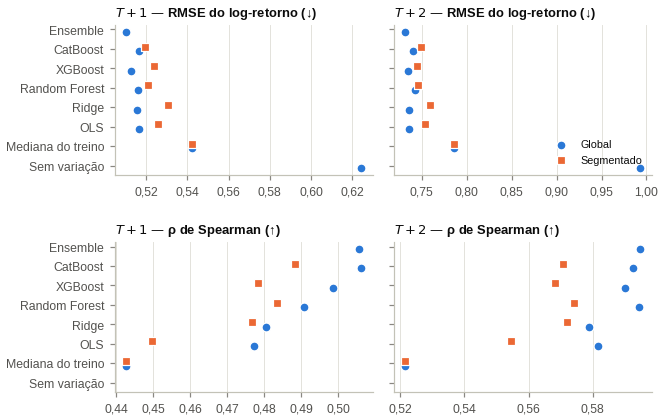

In [7]:
fig, axes = plt.subplots(2, 2, figsize=pl.figsize(11), sharey=True, gridspec_kw={"wspace": 0.08, "hspace": 0.45})
model_order = ["zero", "median", "ols", "ridge", "rf", "xgb", "cat", "ens"]
approach_style = {"Global": (pl.BLUE, "o"), "Segmentado": (pl.ORANGE, "s")}
for col, k in enumerate(HORIZONS):
    h = holdout[holdout["horizon"] == k]
    for row, (metric, title) in enumerate((("RMSE_log", "RMSE do log-retorno (↓)"),
                                           ("spearman", "ρ de Spearman (↑)"))):
        ax = axes[row, col]
        for approach, (color, marker) in approach_style.items():
            d = h[h["approach"] == approach].set_index("model").reindex(model_order)
            if approach == "Segmentado":
                d.loc[["zero", "ens"]] = np.nan
            y = np.arange(len(model_order)) + (0.12 if approach == "Segmentado" else -0.12)
            ax.scatter(d[metric], y, color=color, marker=marker, s=34, label=approach, zorder=3,
                       edgecolor=pl.SURFACE, linewidth=0.8)
        ax.set_yticks(range(len(model_order)), [LABELS[m].split(" (")[0] for m in model_order])
        ax.invert_yaxis()
        ax.xaxis.set_major_formatter(pl.br_formatter(2))
        ax.set_title(f"$T+{k}$ — {title}", fontsize=8.5)
        ax.grid(axis="y", visible=False)
axes[0, 1].legend(loc="lower right", fontsize=7)
FIG.save(fig, "fig02_comparacao_modelos_teste",
         "Desempenho dos modelos no teste final (2023/24): erro e capacidade de ordenação",
         note="Teste nunca utilizado na otimização. 'Sem variação' prevê V_{T+k} = V_T.")
plt.show()

In [8]:
# Diferenças entre algoritmos no teste final: bootstrap pareado (2.000 reamostragens) da diferença
# de RMSE em relação ao CatBoost global. IC de 95% que contém zero = diferença não significativa.
rng = np.random.default_rng(42)
rows = []
for k in HORIZONS:
    h = main[(main["horizon"] == k) & main["is_holdout"]]
    ref = h[(h["approach"] == "Global") & (h["model"] == "cat")].set_index("fbref_player_id")
    idx = rng.integers(0, len(ref), size=(2000, len(ref)))
    for (approach, m), d in h.groupby(["approach", "model"]):
        d = d.set_index("fbref_player_id").reindex(ref.index)
        e_ref, e_m = (ref["y_true"] - ref["y_pred"]).to_numpy(), (d["y_true"] - d["y_pred"]).to_numpy()
        diff = np.sqrt((e_m[idx] ** 2).mean(axis=1)) - np.sqrt((e_ref[idx] ** 2).mean(axis=1))
        rows.append({"horizonte": f"T+{k}", "abordagem": approach, "modelo": LABELS[m],
                     "dif_RMSE_vs_CatBoost_global": float(np.sqrt((e_m ** 2).mean()) - np.sqrt((e_ref ** 2).mean())),
                     "IC95_inf": float(np.quantile(diff, 0.025)), "IC95_sup": float(np.quantile(diff, 0.975))})
boot = pd.DataFrame(rows)
boot["significativo"] = (boot["IC95_inf"] > 0) | (boot["IC95_sup"] < 0)
save_csv(boot, "tab04b_bootstrap_diferencas_rmse", index=False)
boot.round(4)

,horizonte,abordagem,modelo,dif_RMSE_vs_CatBoost_global,IC95_inf,IC95_sup,significativo
0,T+1,Global,CatBoost,0.0000,0.0000,0.0000,False
1,T+1,Global,Ensemble (CatBoost + XGBoost + Ridge),-0.0063,-0.0099,-0.0029,True
2,T+1,Global,Mediana do treino (ingênuo),0.0256,0.0164,0.0349,True
3,T+1,Global,OLS,-0.0004,-0.0073,0.0065,False
4,T+1,Global,Random Forest,-0.0009,-0.0064,0.0049,False
5,T+1,Global,Ridge,-0.0014,-0.0083,0.0056,False
6,T+1,Global,XGBoost,-0.0043,-0.0094,0.0009,False
7,T+1,Global,Sem variação (V_{T+k} = V_T),0.1076,0.0957,0.1189,True
8,T+1,Segmentado,CatBoost,0.0028,-0.0020,0.0074,False
9,T+1,Segmentado,Mediana do treino (ingênuo),0.0256,0.0164,0.0349,True


**Leitura (teste final 2023/24, nunca usado na otimização).**

1. **Todos os modelos superam com folga as referências ingênuas.** O melhor modelo, o *ensemble*
   global, fica assim:

   | Horizonte | RMSE do log-retorno | "Sem variação" | Mediana da categoria | $R^2$ do log-retorno | $\rho$ de Spearman |
   |---|---|---|---|---|---|
   | $T+1$ | 0,510 | 0,624 (−18%) | 0,542 (−6%) | 0,28 | 0,51 |
   | $T+2$ | 0,732 | 0,993 (−26%) | 0,786 (−7%) | 0,37 | 0,59 |

   A mediana da categoria já é uma referência exigente: sozinha, ela captura o ciclo de vida
   ($R^2$ de 0,19 e 0,27).
2. **O *ensemble* é o único modelo significativamente melhor que o CatBoost isolado.** A diferença
   de RMSE é de −0,006 em $T+1$ e de −0,008 em $T+2$, com IC de 95% inteiramente negativo no
   *bootstrap* pareado. Entre os algoritmos individuais, as diferenças continuam não significativas.
   O Ridge e o OLS ficam empatados com os *ensembles* de árvores: a estrutura dominante, formada
   por idade, *momentum*, dinâmica das reavaliações e gap de avaliação, é aproximadamente linear no
   log-retorno. A média de modelos lineares e não lineares, porém, reduz a variância e ganha dos
   dois.
3. **O modelo global supera o segmentado.** A arquitetura segmentada é significativamente pior que
   o CatBoost global em 6 de 10 comparações, e não é melhor em nenhuma. Cada segmento treina com
   uma fração dos dados, de cerca de 40 a 320 observações na primeira dobra.
4. **Ganho das novas variáveis.** Com o mesmo algoritmo, o $R^2$ do CatBoost global no teste passa
   de 0,257 para 0,261 em $T+1$ e de 0,352 para 0,353 em $T+2$. Somado ao *ensemble*, o $R^2$ final
   passa de 0,257 para **0,279** em $T+1$ e de 0,352 para **0,367** em $T+2$. Os ganhos de
   magnitude estão na seção 6.

**Comparação com a especificação.** Os $R^2$ de 0,65–0,87 da Tabela 6.1 da Metodologia são
típicos da estimação do **nível** do valor. O próprio valor justo estimado no notebook 03 atinge
$R^2$ de 0,75. Prever a **variação** fora da amostra, com teste temporal estrito, é um problema mais
difícil. Os $R^2$ de 0,28 e 0,37 devem ser apresentados com essa distinção, que é o diferencial do
estudo.

## 4. Desempenho por categoria (matriz 4 × 3)

O $R^2$ por categoria é calculado sobre todas as dobras de teste agrupadas, porque o teste final
isolado tem poucas observações nas categorias de veteranos. A figura compara os algoritmos dentro
da abordagem segmentada.

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/04_model_training/fig03_r2_por_categoria.png


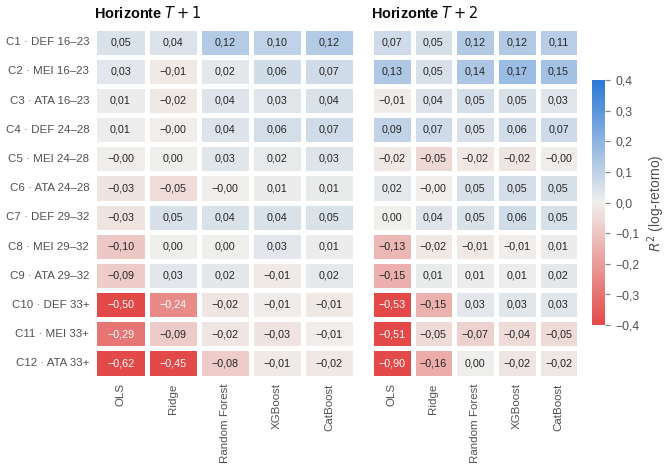

In [9]:
cat_metrics = metrics_by(main[main["model"] != "zero"], ["horizon", "approach", "model", "category"])
save_csv(cat_metrics, "tab06_metricas_por_categoria", index=False)

fig, axes = plt.subplots(1, 2, figsize=pl.figsize(10.5), sharey=True, gridspec_kw={"wspace": 0.06})
for ax, k in zip(axes, HORIZONS):
    d = (cat_metrics[(cat_metrics["horizon"] == k) & (cat_metrics["approach"] == "Segmentado")]
         .pivot(index="category", columns="model", values="R2_log").reindex(index=CATEGORIES, columns=MODELS[1:]))
    d.index = [CAT_LABELS[c] for c in d.index]
    d.columns = [MODEL_LABELS[m] for m in d.columns]
    sns.heatmap(d, annot=pl.annotations(d, 2), fmt="", cmap=pl.DIVERGING, center=0, vmin=-0.4, vmax=0.4,
                linewidths=2, linecolor=pl.SURFACE, cbar=ax is axes[1], ax=ax, annot_kws={"fontsize": 7},
                cbar_kws={"label": "$R^2$ (log-retorno)", "shrink": 0.7})
    ax.set_title(f"Horizonte $T+{k}$")
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(length=0, labelsize=7.5)
    ax.grid(False)
axes[1].collections[0].colorbar.ax.yaxis.set_major_formatter(pl.br_formatter(1))
FIG.save(fig, "fig03_r2_por_categoria",
         "R² do log-retorno por categoria e algoritmo nos modelos segmentados",
         note="Todas as dobras de teste da janela expandida agrupadas. R² < 0: pior que a média do teste.")
plt.show()

### 4.1 Seleção do modelo por categoria e da arquitetura final

Em cada categoria, o algoritmo vencedor é o de menor RMSE média nas dobras de **validação**. Assim
o teste final não interfere na escolha. A abordagem **segmentada composta** usa o vencedor de
cada categoria. A arquitetura final de cada horizonte é a de menor RMSE de validação entre o
melhor modelo global e a composta.

In [10]:
fold_cat = metrics_by(main[(main["approach"] == "Segmentado") & (main["model"] != "zero")],
                      ["horizon", "model", "category", "fold"])
fold_cat = fold_cat.merge(pd.DataFrame([(k, len(folds[k])) for k in HORIZONS], columns=["horizon", "n_folds"]))
val_by_cat = (fold_cat[fold_cat["fold"] < fold_cat["n_folds"]]
              .groupby(["horizon", "category", "model"])["RMSE_log"].mean().rename("rmse_val").reset_index())
winners = val_by_cat.loc[val_by_cat.groupby(["horizon", "category"])["rmse_val"].idxmin()]

seg = main[(main["approach"] == "Segmentado")].merge(winners[["horizon", "category", "model"]],
                                                     on=["horizon", "category", "model"])
composite = seg.assign(approach="Segmentado (melhor por categoria)", model="best")
best_global_model = validation[(validation["approach"] == "Global") & (validation["model"].isin(MODELS[1:] + ["ens"]))]
best_global_model = best_global_model.loc[best_global_model.groupby("horizon")["RMSE_log_validacao"].idxmin()]

final_choice = {}
summary = []
for k in HORIZONS:
    gm = best_global_model.set_index("horizon").loc[k, "model"]
    g_pred = main[(main["horizon"] == k) & (main["approach"] == "Global") & (main["model"] == gm)]
    c_pred = composite[composite["horizon"] == k]
    rows = {}
    for name, p in ((f"Global — {LABELS[gm]}", g_pred), ("Segmentado (melhor por categoria)", c_pred)):
        val = p[p["fold"] < len(folds[k])]
        rows[name] = {"RMSE_log_validacao": md.rmse(val["y_true"], val["y_pred"]),
                      **md.regression_metrics(p[p["is_holdout"]])[["RMSE_log", "R2_log", "spearman", "MAE_pct",
                                                                    "top10_hit_rate", "base_hit_rate"]].to_dict()}
    tab = pd.DataFrame(rows).T
    winner = tab["RMSE_log_validacao"].idxmin()
    final_choice[k] = {"approach": "global" if winner.startswith("Global") else "segmented", "global_model": gm}
    summary.append(tab.assign(horizonte=f"T+{k}", escolhido=lambda d: d.index == winner))
summary = pd.concat(summary).reset_index(names="arquitetura").set_index(["horizonte", "arquitetura"])
save_csv(summary, "tab07_arquitetura_final")
display(summary.round(4))
print(final_choice)

RMSE_log_validacao  RMSE_log  R2_log  spearman  MAE_pct  top10_hit_rate  base_hit_rate  escolhido
horizonte arquitetura                                                                                                                                      
T+1       Global — Ensemble (CatBoost + XGBoost + Ridge)              0.5058    0.5104  0.2787    0.5057  46.2027          0.5288         0.2552       True
          Segmentado (melhor por categoria)                           0.5117    0.5204  0.2503    0.4808  46.7585          0.5288         0.2552      False
T+2       Global — Ensemble (CatBoost + XGBoost + Ridge)              0.7343    0.7317  0.3670    0.5947  81.5675          0.6559         0.2601       True
          Segmentado (melhor por categoria)                           0.7382    0.7414  0.3501    0.5772  82.4284          0.6290         0.2601      False

{1: {'approach': 'global', 'global_model': 'ens'}, 2: {'approach': 'global', 'global_model': 'ens'}}


In [11]:
# Tabela no formato da Tabela 6.1 da especificação: vencedor por categoria e métricas no teste.
rows = []
for k in HORIZONS:
    for c in CATEGORIES:
        w = winners[(winners["horizon"] == k) & (winners["category"] == c)]["model"].iloc[0]
        p = main[(main["horizon"] == k) & (main["approach"] == "Segmentado") & (main["model"] == w) & (main["category"] == c)]
        m_all = md.regression_metrics(p)
        m_hold = md.regression_metrics(p[p["is_holdout"]])
        rows.append({"horizonte": f"T+{k}", "categoria": CAT_LABELS[c], "modelo_vencedor": MODEL_LABELS[w],
                     "R2_log_dobras": m_all["R2_log"], "RMSE_log_dobras": m_all["RMSE_log"],
                     "MAE_pct_dobras": m_all["MAE_pct"], "spearman_dobras": m_all["spearman"],
                     "R2_log_teste": m_hold["R2_log"], "n_teste": int(m_hold["n"])})
table61 = pd.DataFrame(rows)
save_csv(table61, "tab08_vencedor_por_categoria", index=False)
table61.round(3)

,horizonte,categoria,modelo_vencedor,R2_log_dobras,RMSE_log_dobras,MAE_pct_dobras,spearman_dobras,R2_log_teste,n_teste
0,T+1,C1 · DEF 16–23,CatBoost,0.1190,0.6410,90.9600,0.2880,0.1380,175
1,T+1,C2 · MEI 16–23,CatBoost,0.0680,0.6920,99.3050,0.1840,0.1150,188
2,T+1,C3 · ATA 16–23,CatBoost,0.0450,0.6820,88.5310,0.1470,0.0110,178
3,T+1,C4 · DEF 24–28,CatBoost,0.0660,0.4500,34.0250,0.2740,0.0840,317
4,T+1,C5 · MEI 24–28,CatBoost,0.0350,0.4630,33.4370,0.2220,0.0070,247
5,T+1,C6 · ATA 24–28,XGBoost,0.0120,0.5150,40.2660,0.1230,-0.0040,219
6,T+1,C7 · DEF 29–32,Ridge,0.0480,0.3810,20.6150,0.2170,0.0180,195
7,T+1,C8 · MEI 29–32,XGBoost,0.0260,0.3970,19.6730,0.1690,0.0020,132
8,T+1,C9 · ATA 29–32,Random Forest,0.0230,0.4060,20.3780,0.1780,-0.0150,104
9,T+1,C10 · DEF 33+,XGBoost,-0.0060,0.4250,20.0510,0.0300,-0.0130,66


**Leitura.** Dentro de cada categoria, o poder explicativo continua baixo (Figura 3):
- **Jovens (C1–C2):** $R^2$ de 0,07–0,17, com o maior sinal.
- **24–32 anos:** próximo de zero.
- **Veteranos:** negativo para o OLS, que superajusta com 40–90 observações por temporada.

Os modelos explicam sobretudo as diferenças **entre** categorias, somadas ao *momentum* e à
dinâmica de reavaliação. O CatBoost vence em 5 das 6 primeiras categorias em $T+1$. A composição
dos melhores modelos por categoria fica atrás do *ensemble* global (RMSE de validação 0,5117
contra 0,5058 em $T+1$), e por isso a arquitetura global foi adotada nos dois horizontes.

*Sugestão para o texto (Resultados):* "A segmentação em 12 categorias, embora conceitualmente
motivada, reduziu o desempenho fora da amostra: a perda de tamanho amostral por segmento supera o
ganho de especialização. O modelo global com faixa etária e posição como variáveis preserva a
heterogeneidade entre categorias e foi adotado como arquitetura final."

## 5. Estabilidade temporal e calibração do melhor modelo

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/04_model_training/fig04_estabilidade_temporal.png


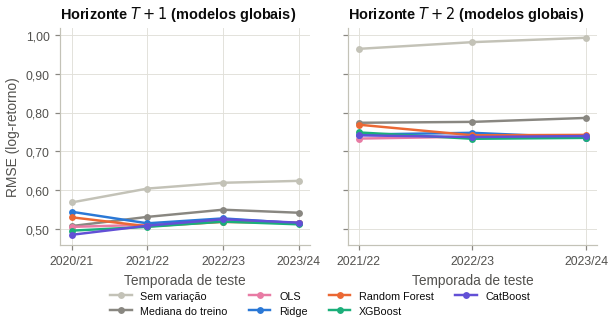

In [12]:
fig, axes = plt.subplots(1, 2, figsize=pl.figsize(6.5), sharey=True, gridspec_kw={"wspace": 0.15})
line_colors = {"zero": pl.NEUTRAL, "median": pl.INK_MUTED, "ols": "#e87ba4", "ridge": pl.BLUE, "rf": pl.ORANGE,
               "xgb": pl.AQUA, "cat": "#6250d6"}
for ax, k in zip(axes, HORIZONS):
    d = per_fold[(per_fold["horizon"] == k) & (per_fold["approach"] == "Global")]
    tests = [sp.season_label(f.test) for f in folds[k]]
    for m, color in line_colors.items():
        s = d[d["model"] == m].sort_values("fold")
        ax.plot(range(len(s)), s["RMSE_log"], color=color, marker="o", markersize=3.5, linewidth=1.6, label=LABELS[m].split(" (")[0])
    ax.set_xticks(range(len(tests)), tests)
    ax.set_xlabel("Temporada de teste")
    ax.set_title(f"Horizonte $T+{k}$ (modelos globais)")
    ax.yaxis.set_major_formatter(pl.br_formatter(2))
axes[0].set_ylabel("RMSE (log-retorno)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=4, fontsize=7)
FIG.save(fig, "fig04_estabilidade_temporal", "RMSE do log-retorno por temporada de teste nos modelos globais")
plt.show()

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/04_model_training/fig05_calibracao_decis.png


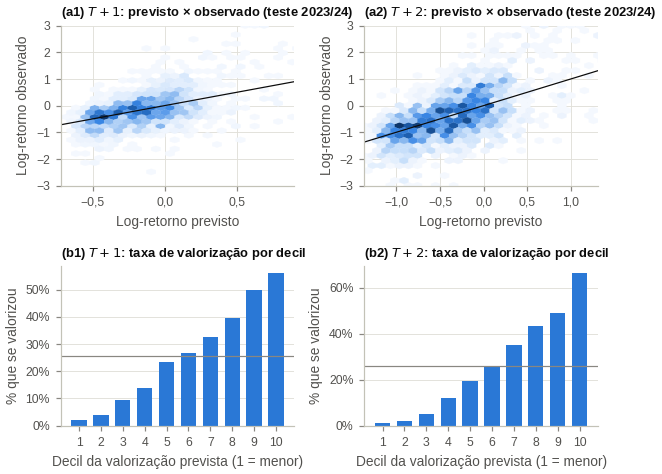

,mediana_dv_pct,pct_valorizou,previsto_mediano_pct,horizonte
decil,,,,
1,-40.0000,1.9000,-43.2000,T+1
2,-35.9000,4.0000,-37.1000,T+1
3,-33.3000,9.3000,-30.9000,T+1
4,-25.0000,13.7000,-24.0000,T+1
5,-20.0000,23.5000,-17.2000,T+1
6,-16.7000,26.8000,-10.7000,T+1
7,-12.0000,32.7000,-3.8000,T+1
8,0.0000,39.5000,3.6000,T+1
9,0.0000,49.7000,13.9000,T+1


In [13]:
def final_predictions(k: int) -> pd.DataFrame:
    if final_choice[k]["approach"] == "segmented":
        return composite[composite["horizon"] == k]
    return main[(main["horizon"] == k) & (main["approach"] == "Global") & (main["model"] == final_choice[k]["global_model"])]


fig, axes = plt.subplots(2, 2, figsize=pl.figsize(12), gridspec_kw={"hspace": 0.5, "wspace": 0.3})
dec_rows = []
for col, k in enumerate(HORIZONS):
    p = final_predictions(k)
    hold = p[p["is_holdout"]]
    ax = axes[0, col]
    hb = ax.hexbin(hold["y_pred"], hold["y_true"].clip(-3, 3), gridsize=28, cmap=pl.SEQUENTIAL, mincnt=1, linewidths=0.2)
    lims = [-2.5, 2.5]
    ax.plot(lims, lims, color=pl.INK, linewidth=0.8)
    ax.set_xlim(hold["y_pred"].quantile(0.005) - 0.1, hold["y_pred"].quantile(0.995) + 0.1)
    ax.set_ylim(-3, 3)
    ax.set_xlabel("Log-retorno previsto")
    ax.set_ylabel("Log-retorno observado")
    ax.set_title(f"(a{col + 1}) $T+{k}$: previsto × observado (teste 2023/24)", fontsize=8.5)
    ax.xaxis.set_major_formatter(pl.br_formatter(1))
    ax.yaxis.set_major_formatter(pl.br_formatter(0))
    # decis de valorização prevista, em todas as dobras de teste (cada temporada ranqueada separadamente)
    p = p.assign(decil=p.groupby("season")["y_pred"].transform(lambda s: pd.qcut(s.rank(method="first"), 10, labels=False) + 1))
    dec = p.groupby("decil").agg(mediana_dv_pct=("dv_pct_true", "median"), pct_valorizou=("y_true", lambda s: (s > 0).mean() * 100),
                                 previsto_mediano_pct=("y_pred", lambda s: np.expm1(s.median()) * 100))
    dec_rows.append(dec.assign(horizonte=f"T+{k}"))
    ax = axes[1, col]
    ax.bar(dec.index, dec["pct_valorizou"], color=pl.BLUE, width=0.7)
    ax.axhline((p["y_true"] > 0).mean() * 100, color=pl.INK_MUTED, linewidth=0.8)
    ax.set_xticks(range(1, 11))
    ax.set_xlabel("Decil da valorização prevista (1 = menor)")
    ax.set_ylabel("% que se valorizou")
    ax.yaxis.set_major_formatter(pl.pct_formatter(0))
    ax.set_title(f"(b{col + 1}) $T+{k}$: taxa de valorização por decil", fontsize=8.5)
    ax.grid(axis="x", visible=False)
save_csv(pd.concat(dec_rows), "tab09_decis_valorizacao_prevista")
FIG.save(fig, "fig05_calibracao_decis",
         "Previsto versus observado no teste final e taxa de valorização observada por decil de valorização prevista",
         note="Em (b), todas as dobras de teste; decis calculados dentro de cada temporada. A linha horizontal é a taxa média.")
plt.show()
pd.concat(dec_rows).round(1)

**Leitura.** A **ordenação** continua sendo o ponto forte. Em todas as dobras de teste:

| | 1º decil | 10º decil | Média |
|---|---|---|---|
| Valorizaram-se até $T+1$ | 1,9% | 56,0% | 25,7% |
| Mediana de $\Delta V\%$ em $T+1$ | −40% | +25% | — |
| Valorizaram-se até $T+2$ | 1,1% | 66,3% | 25,9% |
| Mediana de $\Delta V\%$ em $T+2$ | −67% | +67% | — |

No teste final, dos 10% com maior valorização prevista, 53% se valorizaram em $T+1$ e 66% em $T+2$,
2,1 e 2,5 vezes a taxa média. A nuvem previsto × observado continua mais larga que a amplitude das
previsões. Esse **encolhimento** é tratado pela camada de magnitude da seção seguinte.

## 6. Camada de magnitude: quanto o atleta se valoriza

A previsão do log-retorno é convertida em $\Delta V\%$ pela camada de magnitude (seção inicial). A
tabela compara três versões no teste final:
- a v1, com CatBoost e mediana não recalibrada;
- a v2 com o ponto **mediano**;
- a v2 com o ponto **esperado**.

A figura mostra, por decil da valorização prevista, a média observada de $\Delta V\%$ ao lado da
média prevista. Uma previsão de magnitude bem calibrada acompanha a diagonal.

In [14]:
AGE_OF_CAT = {f"C{b * 3 + p + 1}": band for b, band in enumerate(sp.AGE_BAND_LABELS) for p in range(3)}
magnitude = {k: md.magnitude_layer(final_predictions(k).assign(age_band=lambda d: d["category"].map(AGE_OF_CAT)))
             for k in HORIZONS}
v1 = pd.read_parquet(TABLES / "v1_baseline" / "predictions_best_v1.parquet")
mag_cols = ["RMSE_log", "R2_log", "spearman", "calib_slope", "MAE_pct", "MedAE_pct", "RMSE_pct", "R2_pct",
            "MAE_pct_valorizados", "MAE_eur", "R2_eur", "top10_hit_rate", "top10_median_dv_pct"]
rows = []
for k in HORIZONS:
    hold = magnitude[k][magnitude[k]["is_holdout"]].assign(y_pred=lambda d: d["y_pred_cal"])
    v1h = v1[(v1["horizon"] == k) & v1["is_holdout"]]
    for name, frame, col in (("v1: CatBoost, mediana", v1h, None),
                             ("v2: mediana recalibrada", hold, "dv_pct_pred_median"),
                             ("v2: esperança (smearing)", hold, "dv_pct_pred_mean")):
        rows.append(md.regression_metrics(frame, col)[mag_cols].rename((f"T+{k}", name)))
mag_tab = pd.DataFrame(rows)
mag_tab.index = pd.MultiIndex.from_tuples(mag_tab.index, names=["horizonte", "versao"])
save_csv(mag_tab, "tab11_magnitude_v1_v2")
display(mag_tab.round(3))
smear_tab = pd.DataFrame({f"T+{k}": magnitude[k][magnitude[k]["is_holdout"]].groupby("age_band")["smearing"].first()
                          for k in HORIZONS})
display(smear_tab.round(3).rename_axis("fator de smearing (teste)"))

RMSE_log  R2_log  spearman  calib_slope  MAE_pct  MedAE_pct  RMSE_pct  R2_pct  MAE_pct_valorizados        MAE_eur  R2_eur  top10_hit_rate  top10_median_dv_pct
horizonte versao                                                                                                                                                                                  
T+1       v1: CatBoost, mediana       0.5180  0.2570    0.4970       1.2550  46.3930    23.4630  143.5350  0.1020             118.2070 2,826,386.6030  0.1510          0.5550              33.3330
          v2: mediana recalibrada     0.5130  0.2700    0.5060       1.3250  46.1760    22.7430  144.3400  0.0910             120.3760 2,811,964.2180  0.1430          0.5290              16.6670
          v2: esperança (smearing)    0.5130  0.2700    0.5060       1.3250  48.4630    26.8080  139.5570  0.1510             101.6160 2,980,544.7890  0.1770          0.5290              16.6670
T+2       v1: CatBoost, mediana       0.7400  0.3520    0.5950       1.2620  82.0200    25.8410  426.9450  0.0450             245.4720 4,024,098.4910  0.1760          0.6560              66.6670
          v2: mediana recalibrada     0.7340  0.3630    0.5950       1.1930  81.7640    24.9900  425.2600  0.0520             245.8420 4,019,935.3190  0.1740          0.6560              75.0000
          v2: esperança (smearing)    0.7340  0.3630    0.5950       1.1930  85.6900    31.2790  412.1210  0.1100             211.1070 4,290,114.1060  0.2730          0.6560              75.0000

,T+1,T+2
fator de smearing (teste),,
16–23,1.3730,1.7630
24–28,1.0980,1.1960
29–32,1.0820,1.1780
33+,1.0560,1.1110


I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/04_model_training/fig06_magnitude_decis.png


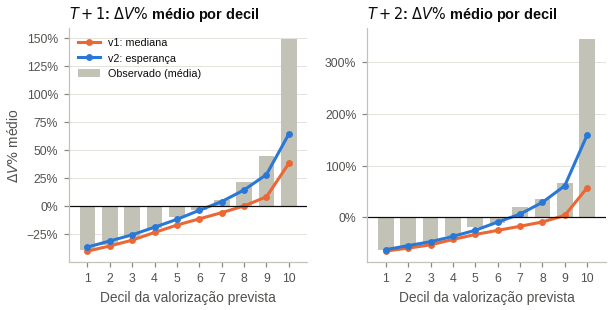

,observado,esperanca,mediana,v1,horizonte
decil,,,,,
1,-39.5000,-36.7000,-41.0000,-40.2000,T+1
2,-34.8000,-31.2000,-36.1000,-35.7000,T+1
3,-28.0000,-25.7000,-31.4000,-30.5000,T+1
4,-19.6000,-18.9000,-26.2000,-23.6000,T+1
5,-9.6000,-12.0000,-21.2000,-17.0000,T+1
6,-3.3000,-3.9000,-16.5000,-11.5000,T+1
7,5.0000,3.9000,-11.4000,-6.0000,T+1
8,21.6000,14.2000,-5.7000,0.0000,T+1
9,44.5000,28.0000,1.6000,8.1000,T+1


In [15]:
fig, axes = plt.subplots(1, 2, figsize=pl.figsize(7), gridspec_kw={"wspace": 0.25})
dec_mag = []
for ax, k in zip(axes, HORIZONS):
    m = magnitude[k][magnitude[k]["fold"] > 1].copy()  # dobras em que a camada tem histórico
    m["decil"] = m.groupby("season")["y_pred_cal"].transform(lambda s: pd.qcut(s.rank(method="first"), 10, labels=False) + 1)
    d = m.groupby("decil").agg(observado=("dv_pct_true", "mean"), esperanca=("dv_pct_pred_mean", "mean"),
                               mediana=("dv_pct_pred_median", "mean"))
    v1m = v1[(v1["horizon"] == k) & (v1["fold"] > 1)].copy()
    v1m["decil"] = v1m.groupby("season")["y_pred"].transform(lambda s: pd.qcut(s.rank(method="first"), 10, labels=False) + 1)
    d["v1"] = v1m.assign(p=np.expm1(v1m["y_pred"]) * 100).groupby("decil")["p"].mean()
    dec_mag.append(d.assign(horizonte=f"T+{k}"))
    ax.bar(d.index, d["observado"], color=pl.NEUTRAL, width=0.7, label="Observado (média)")
    ax.plot(d.index, d["v1"], color=pl.ORANGE, marker="o", markersize=3.5, label="v1: mediana")
    ax.plot(d.index, d["esperanca"], color=pl.BLUE, marker="o", markersize=3.5, label="v2: esperança")
    ax.axhline(0, color=pl.INK, linewidth=0.8)
    ax.set_xticks(range(1, 11))
    ax.yaxis.set_major_formatter(pl.pct_formatter(0))
    ax.set_xlabel("Decil da valorização prevista")
    ax.set_title(f"$T+{k}$: $\\Delta V\\%$ médio por decil")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("$\\Delta V\\%$ médio")
axes[0].legend(loc="upper left", fontsize=7)
save_csv(pd.concat(dec_mag), "tab12_magnitude_por_decil")
FIG.save(fig, "fig06_magnitude_decis",
         "Variação percentual média observada e prevista por decil de valorização prevista (v1 e v2)",
         note="Dobras de teste a partir da 2ª (a camada de magnitude usa apenas as dobras anteriores).")
plt.show()
pd.concat(dec_mag).round(1)

**Leitura: quanto o atleta se valoriza.** A camada de magnitude resolve a maior parte da
subestimação dos ganhos, que era a limitação central da v1.

| Teste 2023/24 | v1 ($T+1$) | v2: esperança ($T+1$) | v1 ($T+2$) | v2: esperança ($T+2$) |
|---|---|---|---|---|
| $R^2$ em $\Delta V\%$ | 0,102 | **0,151** (+48%) | 0,045 | **0,110** (×2,4) |
| RMSE em $\Delta V\%$ (p.p.) | 143,5 | **139,6** | 426,9 | **412,1** |
| MAE entre os que se valorizaram (p.p.) | 118,2 | **101,6** (−14%) | 245,5 | **211,1** (−14%) |
| $R^2$ em ΔV (€) | 0,151 | **0,177** | 0,176 | **0,273** (+55%) |

A Figura 6 mostra o efeito por decil. No 10º decil de $T+1$, o $\Delta V\%$ médio previsto sobe de
+38% (v1) para +64% (v2), contra +149% observados. No 9º decil, de +8% para +28%, contra +45%
observados. Em $T+2$, o 9º decil passa a ser previsto quase sem viés (+61% contra +67%).

*Por que funciona.* Há dois mecanismos.
- **Retransformação.** $e^{\hat y}-1$ estima a variação **mediana**, enquanto a média de
  $V_{T+k}/V_T$ é maior por causa da cauda direita. O fator de Duan corrige isso, e cresce com a
  incerteza: 1,37 para 16–23 anos e 1,06 para 33+ em $T+1$; 1,76 e 1,11 em $T+2$. Em outras
  palavras, os jovens têm a distribuição de valorização mais assimétrica.
- **Novas *features*.** A dinâmica de reavaliações e o gap de avaliação aumentam a dispersão das
  previsões nos extremos.

*A troca entre mediana e esperança.* A esperança melhora as métricas quadráticas e as somas em €,
mas piora levemente o erro absoluto: o MAE em $\Delta V\%$ vai de 46,4 para 48,5 p.p. em $T+1$. A
mediana recalibrada tem o **menor erro típico** (erro absoluto mediano de 22,7 p.p. em $T+1$ e 25,0
em $T+2$). Recomenda-se reportar as duas, com papéis distintos:
- **mediana:** valor central mais provável, para a comunicação ao *scout*;
- **esperança:** retorno esperado, para orçamento e carteira de atletas.

*O que continua difícil.* Os maiores saltos (+150% a +350% em média no decil superior) seguem
subestimados. A inclinação de calibração no teste é 1,33 em $T+1$: as previsões ainda são
comprimidas. Esses saltos dependem de eventos não observáveis em $T$, como transferências, uma
explosão de desempenho ou a primeira convocação. A forma adequada de comunicá-los é o intervalo de
previsão (seção 7).

## 7. Intervalos de previsão (P10–P90)

O intervalo de 80% traduz a incerteza em cenários de valorização: pessimista (P10), central e
otimista (P90). Os quantis brutos do CatBoost são conformalizados com as dobras anteriores, para
que a cobertura empírica se aproxime de 80%.

n  cobertura  cobertura_nominal  largura_mediana_pp  abaixo_do_inferior  acima_do_superior  pinball_q10  pinball_q90
horizonte intervalo      avaliacao                                                                                                                                  
T+1       bruto          teste 2023/24 1,912.0000     0.7830             0.8000             98.3950              0.1240             0.0930       0.0870       0.0910
                         dobras ≥ 2    5,792.0000     0.7680             0.8000             95.1350              0.1270             0.1050       0.0840       0.0950
          conformalizado teste 2023/24 1,912.0000     0.8220             0.8000            110.6420              0.1030             0.0750       0.0860       0.0920
                         dobras ≥ 2    5,792.0000     0.8160             0.8000            108.8150              0.0990             0.0860       0.0840       0.0950
T+2       bruto          teste 2023/24 1,865.0000     0.7590             0.8000            113.2720              0.1350             0.1070       0.1290       0.1270
                         dobras ≥ 2    3,758.0000     0.7290             0.8000            107.5640              0.1470             0.1250       0.1300       0.1300
          conformalizado teste 2023/24 1,865.0000     0.8600             0.8000            160.7800              0.0760             0.0640       0.1280       0.1320
                         dobras ≥ 2    3,758.0000     0.8580             0.8000            162.4000              0.0740             0.0680       0.1280       0.1320

I         plotting | figura gravada  path=/home/alvaro/Documents/TCC/football-analytics/reports/figures/04_model_training/fig07_intervalos_previsao.png


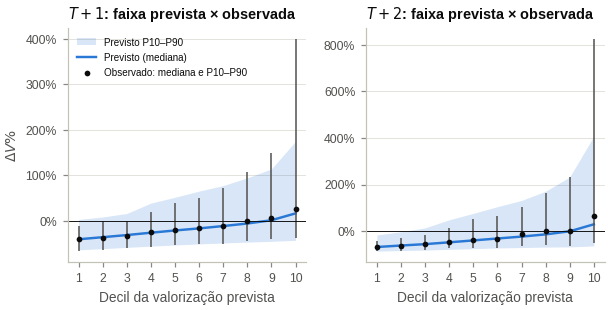

In [16]:
qpred = pd.concat([r["predictions"].assign(horizon=r["task"].horizon, q=r["task"].extra_label) for r in quantiles])
qwide = qpred.pivot_table(index=["horizon", "season", "fbref_player_id"], columns="q", values="y_pred").reset_index()
intervals, int_rows = {}, []
for k in HORIZONS:
    m = magnitude[k].merge(qwide[qwide["horizon"] == k].drop(columns="horizon"), on=["season", "fbref_player_id"])
    # o intervalo deve conter o ponto central recalibrado
    m["q10"], m["q90"] = np.minimum(m["q10"], m["y_pred_cal"]), np.maximum(m["q90"], m["y_pred_cal"])
    m = md.conformal_interval(m, "q10", "q90", 0.8)
    intervals[k] = m.assign(horizon=k)
    for name, lo, hi in (("bruto", "q10", "q90"), ("conformalizado", "q10_conf", "q90_conf")):
        for scope, frame in (("teste 2023/24", m[m["is_holdout"]]), ("dobras ≥ 2", m[m["fold"] > 1])):
            int_rows.append(md.interval_metrics(frame, lo, hi).rename((f"T+{k}", name, scope)))
int_tab = pd.DataFrame(int_rows)
int_tab.index = pd.MultiIndex.from_tuples(int_tab.index, names=["horizonte", "intervalo", "avaliacao"])
save_csv(int_tab, "tab13_intervalos_previsao")
display(int_tab.round(3))

fig, axes = plt.subplots(1, 2, figsize=pl.figsize(7), sharey=False, gridspec_kw={"wspace": 0.25})
for ax, k in zip(axes, HORIZONS):
    m = intervals[k][intervals[k]["fold"] > 1].copy()
    m["decil"] = m.groupby("season")["y_pred_cal"].transform(lambda s: pd.qcut(s.rank(method="first"), 10, labels=False) + 1)
    g = m.groupby("decil")
    obs = g["dv_pct_true"].quantile([0.1, 0.5, 0.9]).unstack()
    pred_lo = g["q10_conf"].median().pipe(np.expm1) * 100
    pred_hi = g["q90_conf"].median().pipe(np.expm1) * 100
    pred_mid = g["y_pred_cal"].median().pipe(np.expm1) * 100
    x = obs.index.to_numpy()
    ax.fill_between(x, pred_lo, pred_hi, color=pl.BLUE, alpha=0.18, linewidth=0, label="Previsto P10–P90")
    ax.plot(x, pred_mid, color=pl.BLUE, linewidth=1.6, label="Previsto (mediana)")
    ax.vlines(x, obs[0.1], obs[0.9], color=pl.INK_SECONDARY, linewidth=1)
    ax.scatter(x, obs[0.5], color=pl.INK, s=14, zorder=3, label="Observado: mediana e P10–P90")
    ax.axhline(0, color=pl.INK, linewidth=0.6)
    ax.set_xticks(range(1, 11))
    ax.yaxis.set_major_formatter(pl.pct_formatter(0))
    ax.set_xlabel("Decil da valorização prevista")
    ax.set_title(f"$T+{k}$: faixa prevista × observada")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("$\\Delta V\\%$")
axes[0].legend(loc="upper left", fontsize=6.5)
FIG.save(fig, "fig07_intervalos_previsao",
         "Intervalo de previsão de 80% (P10–P90) e distribuição observada da variação percentual por decil",
         note="Quantis do CatBoost conformalizados com as dobras anteriores; dobras de teste a partir da 2ª.")
plt.show()

**Leitura.** O intervalo de 80% conformalizado tem cobertura de **82% em $T+1$** e **86% em
$T+2$** no teste final. Os quantis brutos do CatBoost cobriam 78% e 76%, abaixo do nominal. A
conformalização sequencial corrige a subcobertura sem olhar o teste.

A largura mediana é de cerca de 110 p.p. em $T+1$ e 160 p.p. em $T+2$. A incerteza é grande e
deve ser comunicada como tal. A Figura 7 mostra que o intervalo se abre para cima nos decis
superiores: a previsão central é modesta, mas o cenário otimista (P90) é amplo, de +170% no 10º
decil de $T+1$ e cerca de +400% em $T+2$. Para o modelo *buy-low*, essa assimetria é a informação
relevante. Um atleta do decil superior tem perda limitada (P10 em torno de −40%) e um ganho
potencial várias vezes maior.

*Sugestão para o texto:* "Além do ponto previsto, o modelo fornece um intervalo de 80% calibrado
(cobertura empírica de 82–86% no teste), que expressa a magnitude da valorização como cenários
pessimista, central e otimista."

## 8. Robustez: variáveis contratuais sujeitas a *look-ahead*

O XGBoost global é reestimado com o tempo restante de contrato e o status Bosman reconstruídos
(notebook 03), com os mesmos hiperparâmetros. O ganho de desempenho não deve ser lido como valor
preditivo legítimo. Ele é um **limite superior contaminado** por informação posterior a $T$, e é
apresentado para dar transparência ao tratamento dessas variáveis.

In [17]:
rob = metrics_by(pred[(pred["approach"] == "Global") & (pred["model"] == "xgb") & pred["is_holdout"]],
                 ["horizon", "extra"])
rob["especificacao"] = rob["extra"].map({"": "Principal (sem contrato reconstruído)", "lookahead": "Com contrato reconstruído"})
rob = rob.set_index(["horizon", "especificacao"])[["RMSE_log", "R2_log", "spearman", "top10_hit_rate"]]
save_csv(rob, "tab10_robustez_lookahead")
rob.round(4)

RMSE_log  R2_log  spearman  top10_hit_rate
horizon especificacao                                                                    
1       Principal (sem contrato reconstruído)    0.5125  0.2728    0.4988          0.5183
        Com contrato reconstruído                0.5097  0.2806    0.5077          0.5393
2       Principal (sem contrato reconstruído)    0.7350  0.3613    0.5901          0.6290
        Com contrato reconstruído                0.7293  0.3712    0.5963          0.6613

**Leitura.** Com o tempo restante de contrato e o status Bosman reconstruídos, o $R^2$ do XGBoost
global vai de 0,273 para 0,281 em $T+1$ e de 0,361 para 0,371 em $T+2$. O ganho é pequeno, e é um
limite superior, porque essas variáveis carregam informação posterior a $T$. Isso confirma que
excluí-las do vetor principal custa pouco. O efeito Bosman não pôde ser medido de forma limpa com
dados públicos.

## 9. Modelos finais e gravação

In [18]:
FINAL.mkdir(parents=True, exist_ok=True)
manifest = {"created": pd.Timestamp.now().isoformat(timespec="seconds"), "target": "log-retorno ln(V_{T+k}/V_T)",
            "numeric_features": list(NUMERIC), "horizons": {}}
for k in HORIZONS:
    entry = {"approach": final_choice[k]["approach"], "global": {}, "segments": {}}
    gm = final_choice[k]["global_model"]
    global_members = ENSEMBLE if gm == "ens" else [gm]
    entry["global_members"] = global_members
    for scope, model_key in [("global", m) for m in global_members] + [
            (c, winners[(winners["horizon"] == k) & (winners["category"] == c)]["model"].iloc[0]) for c in CATEGORIES]:
        task = md.Task(k, scope, model_key, NUMERIC, CAT_GLOBAL if scope == "global" else CAT_SEGMENT)
        spec = SPECS["global" if scope == "global" else "segment"][model_key]
        params = by_key[(k, scope, model_key)]["params"]
        model = md.fit_final(spec, params, task, panel)
        path = FINAL / f"T{k}" / f"{scope}_{model_key}.joblib"
        path.parent.mkdir(parents=True, exist_ok=True)
        joblib.dump({"model": model, "task": task, "params": params}, path)
        info = {"model": model_key, "label": MODEL_LABELS[model_key], "params": params,
                "path": str(path.relative_to(paths.root)), "categorical": list(task.categorical),
                "numeric": list(task.numeric),
                "n_train": int(md.task_data(panel, task).shape[0])}
        if scope == "global":
            entry["global"][model_key] = info
        else:
            entry["segments"][scope] = info
    # quantis e camada de magnitude para uso no notebook 05 (estimada em todas as dobras de teste)
    for qt, fixed in q_tasks:
        if qt.horizon == k:
            qm = md.fit_final(SPECS["global"]["cat"], fixed, qt, panel)
            qpath = FINAL / f"T{k}" / f"global_cat_{qt.extra_label}.joblib"
            joblib.dump({"model": qm, "task": qt, "params": fixed}, qpath)
            entry[qt.extra_label] = {"path": str(qpath.relative_to(paths.root)), "params": fixed}
    m = magnitude[k]
    b, a = np.polyfit(m["y_pred"], m["y_true"], 1)
    ratio = np.exp(m["y_true"] - (a + b * m["y_pred"]))
    entry["magnitude_layer"] = {"a": float(a), "b": float(b),
                                "smearing_by_age_band": ratio.groupby(m["age_band"]).mean().round(4).to_dict(),
                                "conformal_adj": float(intervals[k]["conformal_adj"].iloc[-1])}
    manifest["horizons"][f"T{k}"] = entry
(FINAL / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2, default=str), encoding="utf-8")

oof = pred.merge(panel[["season", "fbref_player_id", "fb_player", "fb_team", "league", "age_band", "position_group"]],
                 on=["season", "fbref_player_id"], how="left")
oof["dv_pct_pred"] = np.expm1(oof["y_pred"]) * 100
oof["dv_pred"] = oof["value_T"] * np.expm1(oof["y_pred"])
save_table(oof, PROCESSED_OUT / "predictions_oof.parquet",
           source="notebook 04: previsões fora da amostra (janela expandida) de todos os modelos")
best = pd.concat([intervals[k] for k in HORIZONS])
best = best.merge(panel[["season", "fbref_player_id", "fb_player", "fb_team", "league", "position_group"]],
                  on=["season", "fbref_player_id"], how="left")
best["dv_pct_pred"] = best["dv_pct_pred_median"]
save_table(best, PROCESSED_OUT / "predictions_best.parquet",
           source="notebook 04: previsões fora da amostra da arquitetura final de cada horizonte")
FIG.write_index()
print(json.dumps({k: {"arquitetura": v["approach"], "global": [g["label"] for g in v["global"].values()],
                      "segmentos": {c: s["label"] for c, s in v["segments"].items()}}
                  for k, v in manifest["horizons"].items()}, ensure_ascii=False, indent=1))

I               io | tabela gravada  path=/home/alvaro/Documents/TCC/football-analytics/data/processed/predictions_oof.parquet rows=174252 cols=22


I               io | tabela gravada  path=/home/alvaro/Documents/TCC/football-analytics/data/processed/predictions_best.parquet rows=13404 cols=30


{
 "T1": {
  "arquitetura": "global",
  "global": [
   "CatBoost",
   "XGBoost",
   "Ridge"
  ],
  "segmentos": {
   "C1": "CatBoost",
   "C2": "CatBoost",
   "C3": "CatBoost",
   "C4": "CatBoost",
   "C5": "CatBoost",
   "C6": "XGBoost",
   "C7": "Ridge",
   "C8": "XGBoost",
   "C9": "Random Forest",
   "C10": "XGBoost",
   "C11": "Mediana do treino (ingênuo)",
   "C12": "XGBoost"
  }
 },
 "T2": {
  "arquitetura": "global",
  "global": [
   "CatBoost",
   "XGBoost",
   "Ridge"
  ],
  "segmentos": {
   "C1": "Random Forest",
   "C2": "XGBoost",
   "C3": "Random Forest",
   "C4": "OLS",
   "C5": "CatBoost",
   "C6": "XGBoost",
   "C7": "XGBoost",
   "C8": "Mediana do treino (ingênuo)",
   "C9": "CatBoost",
   "C10": "XGBoost",
   "C11": "XGBoost",
   "C12": "XGBoost"
  }
 }
}


## 10. Síntese para o artigo

**Arquitetura final (v2):** *ensemble* global (média de CatBoost, XGBoost e Ridge) nos dois
horizontes, com camada de magnitude e intervalo conformal de 80%.

| Teste 2023/24 | v1 $T+1$ | **v2 $T+1$** | v1 $T+2$ | **v2 $T+2$** |
|---|---|---|---|---|
| RMSE do log-retorno | 0,518 | **0,510** | 0,740 | **0,732** |
| $R^2$ do log-retorno | 0,257 | **0,279** | 0,352 | **0,367** |
| $\rho$ de Spearman | 0,497 | **0,506** | 0,595 | 0,595 |
| $R^2$ em $\Delta V\%$ (esperança) | 0,102 | **0,151** | 0,045 | **0,110** |
| $R^2$ em ΔV (€) (esperança) | 0,151 | **0,177** | 0,176 | **0,273** |
| MAE entre os que se valorizaram (p.p.) | 118,2 | **101,6** | 245,5 | **211,1** |
| Erro absoluto mediano em $\Delta V\%$ (mediana) | 23,5 | **22,7** | 25,8 | **25,0** |
| Cobertura do intervalo de 80% | — | **82%** | — | **86%** |

**O que mudou da v1 para a v2**
1. **Variáveis:**
   - oito variáveis de **dinâmica das reavaliações** do Transfermarkt (distância ao pico, variação
     em seis meses, última revisão, revisões para cima e para baixo, volatilidade);
   - o **gap de avaliação** (valor justo pelo desempenho menos $V_T$), que dá forma empírica à
     premissa *buy-low*.
2. ***Ensemble*** de modelos lineares e não lineares: o único ganho significativo sobre o melhor
   modelo isolado.
3. **Camada de magnitude:** recalibração e *smearing* de Duan por faixa etária. É a maior melhoria
   na estimativa de **quanto**: o $R^2$ em $\Delta V\%$ sobe 48% em $T+1$ e 2,4 vezes em $T+2$, e
   o $R^2$ em € sobe 55% em $T+2$.
4. **Intervalos conformalizados**, que comunicam a incerteza da magnitude como cenários.

**Limitações remanescentes**
- Os maiores saltos de valor continuam subestimados (inclinação de calibração > 1). Eles dependem
  de eventos não observáveis em $T$.
- Há cortes computacionais nos hiperparâmetros (seção inicial).
- As variáveis contratuais ficaram fora do vetor principal por causa do *look-ahead*.

**Artefatos para o notebook 05**
- `models/04_model_training/final/manifest.json`: os três componentes do *ensemble*, os quantis,
  os parâmetros da camada de magnitude e os 12 modelos segmentados de cada horizonte.
- `data/processed/predictions_best.parquet`: previsões com mediana, esperança e intervalo.